# Authors: The scikit-learn developers


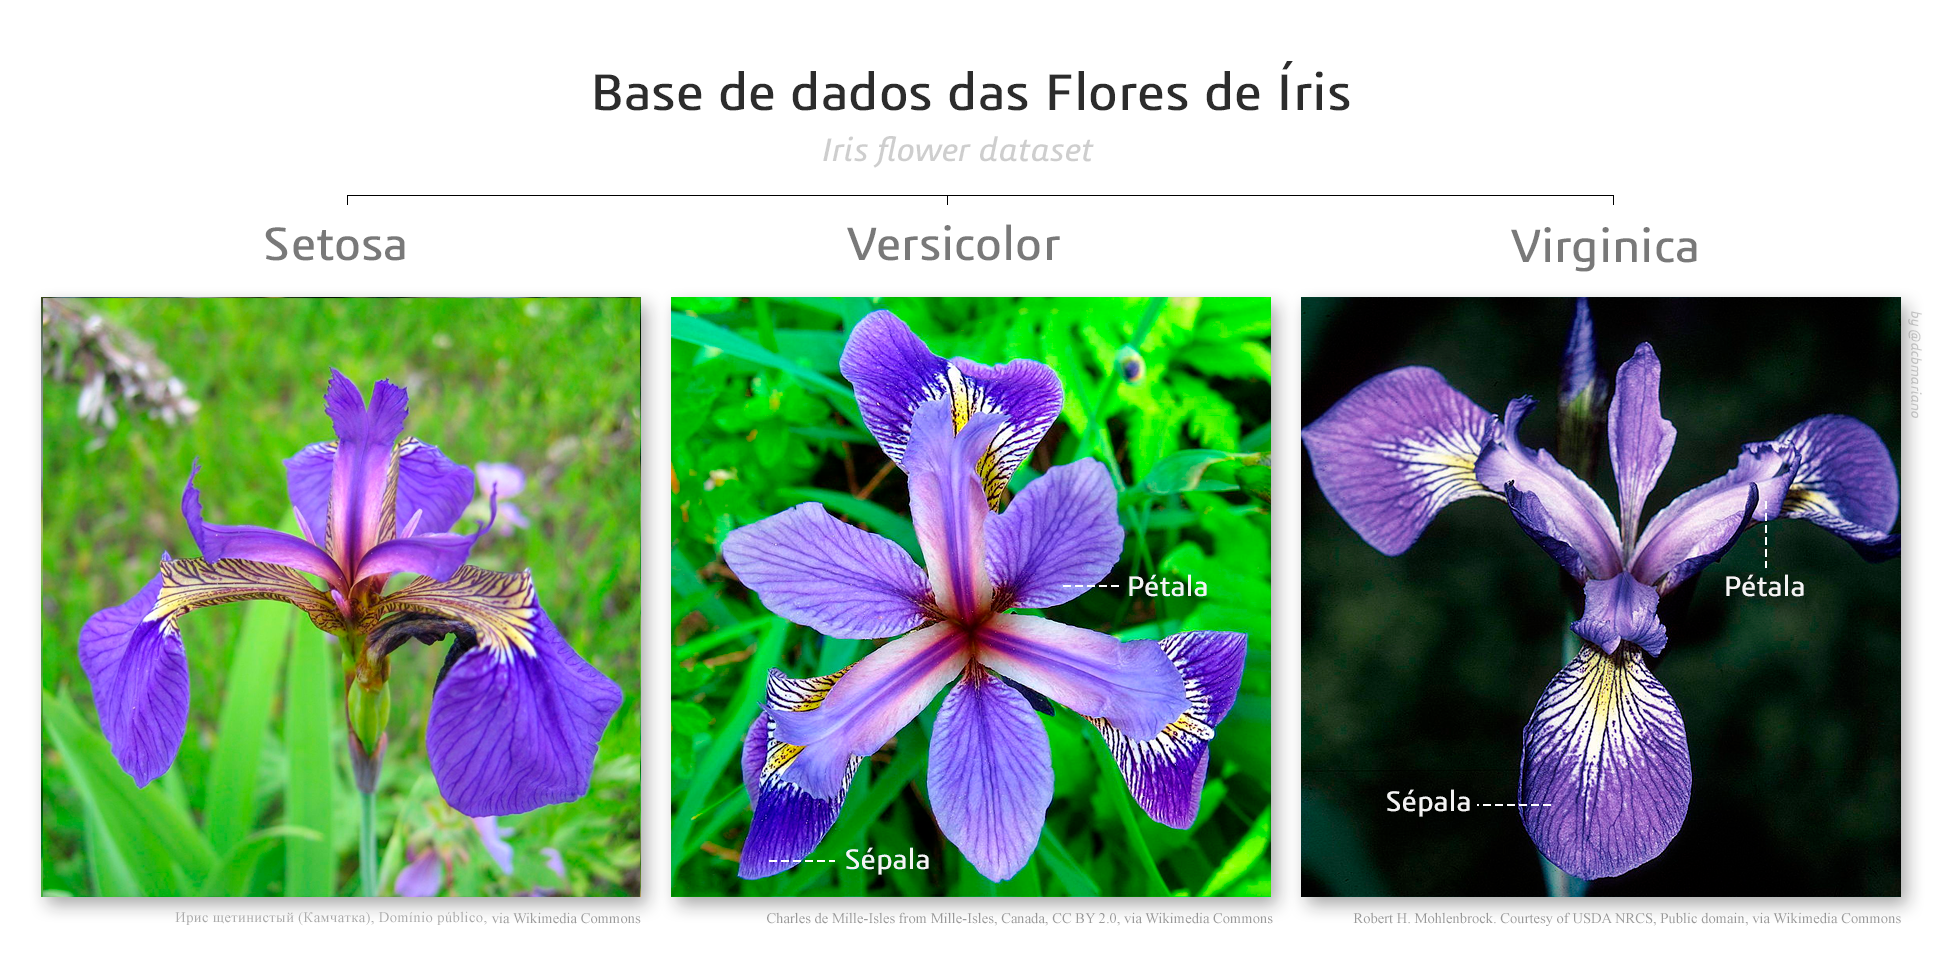

In [1]:
# Importar bibliotecas
import pandas as pd
from sklearn import datasets

# Carregar o dataset Iris
iris = datasets.load_iris()

# Criar DataFrame com as colunas em português
iris_df = pd.DataFrame(data=iris.data, columns=[
    "Comprimento Sépala (cm)", "Largura Sépala (cm)",
    "Comprimento Pétala (cm)", "Largura Pétala (cm)"
])

# Adicionar a coluna de espécies com os nomes das classes
iris_df["Espécie"] = [iris.target_names[label] for label in iris.target]

# Garantir que todas as 3 espécies apareçam nas primeiras 10 linhas
iris_df_sample = iris_df.groupby("Espécie").head(4)  # Pegando 4 de cada para garantir variedade

# Exibir as 10 primeiras linhas garantindo diversidade nas espécies
iris_df_sample.head(10)



,Comprimento Sépala (cm),Largura Sépala (cm),Comprimento Pétala (cm),Largura Pétala (cm),Espécie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
50,7.0,3.2,4.7,1.4,versicolor
51,6.4,3.2,4.5,1.5,versicolor
52,6.9,3.1,4.9,1.5,versicolor
53,5.5,2.3,4.0,1.3,versicolor
100,6.3,3.3,6.0,2.5,virginica
101,5.8,2.7,5.1,1.9,virginica


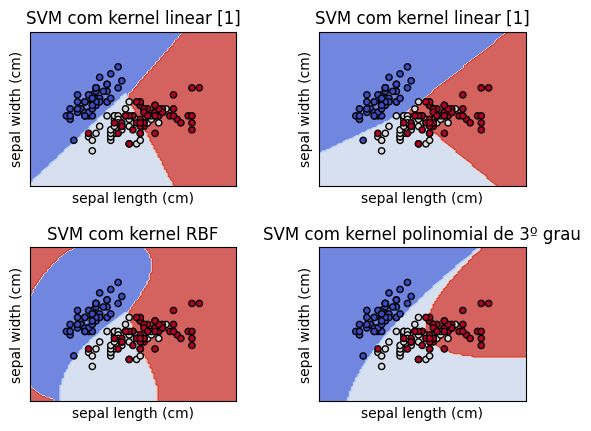

In [2]:
import matplotlib.pyplot as plt
import pandas as pd


from sklearn import datasets, svm
from sklearn.inspection import DecisionBoundaryDisplay

# import dos dados
iris = datasets.load_iris()
# Peguando os dois primeiros atributos. /Poderíamos evitar isso usando um conjunto de dados de duas dimensões/
X = iris.data[:, :2]
y = iris.target

# Criando uma SVM e ajustamos os dados.
C = 1.0  # SVM parâmetro de regularização
models = (
    svm.SVC(kernel="linear", C=C),
    svm.LinearSVC(C=C, max_iter=10000),
    svm.SVC(kernel="rbf", gamma=0.7, C=C),
    svm.SVC(kernel="poly", degree=3, gamma="auto", C=C),
)
models = (clf.fit(X, y) for clf in models)

# títulos para o gráfico
titles = (
    "SVM com kernel linear [1]",
    "SVM com kernel linear [1]",
    "SVM com kernel RBF",
    "SVM com kernel polinomial de 3º grau",
)

# Ajustando o grid 2x2 do gráfico.
fig, sub = plt.subplots(2, 2)
plt.subplots_adjust(wspace=0.4, hspace=0.4)

X0, X1 = X[:, 0], X[:, 1]

for clf, title, ax in zip(models, titles, sub.flatten()):
    disp = DecisionBoundaryDisplay.from_estimator(
        clf,
        X,
        response_method="predict",
        cmap=plt.cm.coolwarm,
        alpha=0.8,
        ax=ax,
        xlabel=iris.feature_names[0],
        ylabel=iris.feature_names[1],
    )
    ax.scatter(X0, X1, c=y, cmap=plt.cm.coolwarm, s=20, edgecolors="k")
    ax.set_xticks(())
    ax.set_yticks(())
    ax.set_title(title)

plt.show()